# Notebook 2: a small HQMM step on Azure Quantum

This notebook sends **one day** of a **2-asset** Q-E model to Azure Quantum through Qiskit, and compares the measured outcome frequencies with the exact probabilities.

**Before it can run on Azure you need** (ask Sir / the course for these):
1. An Azure subscription and an **Azure Quantum workspace**, with at least one provider added (for example IonQ, Quantinuum or Rigetti).
2. The workspace **resource ID** and **location**, from the workspace overview page in the Azure portal.
3. Credits for the hardware target. Simulator targets are usually free or very cheap, so start with one.

**Until then** the notebook still runs: with no credentials it does a **dry run** on Qiskit's local Aer simulator, so everything except the Azure call can be checked. The Azure cells have not been tested against a live workspace.

**What hardware can and cannot do here.** Real devices today are noisy and have few qubits, and most do not allow measuring in the middle of a circuit. So this runs only a single day with measurement at the end, and it starts the register in a fixed basis state instead of the maximally mixed state the full model uses. It is a demonstration, not a regime-detection run. We make no claim of quantum advantage.

In [1]:
# --- setup: find (or clone) the repo and make sure the packages are installed ---
import importlib, os, pathlib, subprocess, sys

REPO_URL = "https://github.com/Sarahsusangeorge/fds-eqhqmm"
BRANCH = "sarah/qiskit-backend"          # change to "main" once the Qiskit branch is merged

def has_repo(p):
    return (p / "models" / "hqmm" / "qiskit_backend.py").exists()

root = pathlib.Path.cwd()
if not has_repo(root):
    if has_repo(root.parent):
        root = root.parent
    else:
        subprocess.run(["git", "clone", "--depth", "1", "-b", BRANCH, REPO_URL, "fds-eqhqmm"], check=True)
        root = pathlib.Path("fds-eqhqmm").resolve()
os.chdir(root)
sys.path.insert(0, str(root))

need = {"qiskit": "qiskit", "qiskit_aer": "qiskit-aer", "torch": "torch", "scipy": "scipy",
        "pandas": "pandas", "yaml": "pyyaml", "sklearn": "scikit-learn", "matplotlib": "matplotlib"}
missing = [pip for mod, pip in need.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
print("repo:", root)


repo: /tmp/claude-0/-home-claude/5eecb312-ddfd-5008-99e7-acf20aaac6b0/scratchpad/wt


In [2]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from models.base import Fold
from models.hqmm import qiskit_backend as qb
from models.hqmm.engine import LBFGSConfig, register_kraus_table, unitary_columns
from models.hqmm.equivariant import EquivariantBuilder
from models.hqmm.generic import GenericBuilder
from models.hqmm.model import HQMMModel
from tests.helpers import fake_market


def make_model(kind, K=3, fast=True):
    cfg = LBFGSConfig(rounds=2, max_iter=3) if fast else LBFGSConfig()
    if kind == "qe":
        return HQMMModel(lambda n: EquivariantBuilder(2, n, layers=2), K=K, name="Q-E", n_restarts=1,
                         shared_measurement=True, symbol_mode="train_vol", config=cfg)
    return HQMMModel(lambda n: GenericBuilder(2, n, layers=3), K=K, name="Q-G", n_restarts=1,
                     shared_measurement=False, symbol_mode="train_vol", config=cfg)


def fit(kind, n_assets, T=1700, seed=0):
    md, _ = fake_market(T=T, n=n_assets, seed=seed)
    T = md.T                      # a few days are lost to the feature warm-up
    n_tr, n_va = int(T * 0.6), int(T * 0.75)
    fold = Fold(0, np.arange(n_tr), np.arange(n_tr, n_va), np.arange(n_va, T))
    sym0 = np.zeros((T, md.n), dtype=int)
    m = make_model(kind).fit(md, sym0, fold, seed=seed)
    return m, md, fold, sym0


def exact_table(model, n_assets):
    with torch.no_grad():
        return register_kraus_table(unitary_columns(model.builder), model.measurement.rows(), 2, n_assets).numpy()

import os
N = 2          # keep the circuit small for real devices
K = 3
SHOTS = 1000   # hardware shots cost credits; raise only if needed

# ---- Azure settings: fill in, or set these as environment variables ----
RESOURCE_ID = os.environ.get("AZURE_QUANTUM_RESOURCE_ID", "")
LOCATION    = os.environ.get("AZURE_QUANTUM_LOCATION", "")
TARGET      = os.environ.get("AZURE_QUANTUM_TARGET", "ionq.simulator")   # start with a simulator target, then a QPU
USE_AZURE   = bool(RESOURCE_ID and LOCATION)
print("mode:", "Azure Quantum, target " + TARGET if USE_AZURE else "DRY RUN on the local Aer simulator (no Azure credentials set)")


mode: DRY RUN on the local Aer simulator (no Azure credentials set)


## 1. Train a small Q-E model and build one circuit

The register starts in basis state |00> and the asset outcomes are measured once, at the end.

In [3]:
m, md, fold, sym0 = fit("qe", N)
ref = exact_table(m, N)
qc = qb.build_step_circuit(m.builder, m.measurement, 2, N, measure=True)
print(qc.draw("text", fold=110))
est = qb.circuit_resources(qc)
print(f"size in basic gates (rz, sx, x, cx): {est['qubits']} qubits, {est['cx']} CX gates, depth {est['depth']}")
print("Real devices have error rates of roughly 0.1% to 1% per two-qubit gate, so this many CX gates will push the "
      "measured result well away from the exact one. That is expected and is the point of reporting both.")
s0 = 0
psi0 = np.zeros(4); psi0[s0] = 1
p_exact = np.array([np.linalg.norm(ref[y] @ psi0) ** 2 for y in range(K ** N)])
print("exact outcome probabilities (sum %.4f):" % p_exact.sum(), np.round(p_exact, 3))


         ┌────┐                                
  reg_0: ┤3   ├────────────────────────────────
         │    │                                
  reg_1: ┤2   ├────────────────────────────────
         │  V │┌────────┐                      
asset_0: ┤1   ├┤2       ├──────────────────────
         │    ││        │┌────────┐            
asset_1: ┤0   ├┤        ├┤2       ├────────────
         └────┘│  read0 ││        │┌─┐         
 anc0_0: ──────┤1       ├┤        ├┤M├─────────
               │        ││        │└╥┘┌─┐      
 anc0_1: ──────┤0       ├┤  read1 ├─╫─┤M├──────
               └────────┘│        │ ║ └╥┘┌─┐   
 anc1_0: ────────────────┤1       ├─╫──╫─┤M├───
                         │        │ ║  ║ └╥┘┌─┐
 anc1_1: ────────────────┤0       ├─╫──╫──╫─┤M├
                         └────────┘ ║  ║  ║ └╥┘
   y0: 2/═══════════════════════════╩══╩══╬══╬═
                                    0  1  ║  ║ 
   y1: 2/═════════════════════════════════╩══╩═
                                        

## 2. Choose the backend

In [4]:
from qiskit import transpile

if USE_AZURE:
    # pip install azure-quantum[qiskit]   (done automatically below if missing)
    if importlib.util.find_spec("azure.quantum") is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "azure-quantum[qiskit]"], check=True)
    from azure.quantum.qiskit import AzureQuantumProvider
    provider = AzureQuantumProvider(resource_id=RESOURCE_ID, location=LOCATION)
    print("targets in this workspace:", [b.name() for b in provider.backends()])
    backend = provider.get_backend(TARGET)
else:
    from qiskit_aer import AerSimulator
    backend = AerSimulator()

tqc = transpile(qc, backend, optimization_level=1)
ops = tqc.count_ops()
print(f"after compiling for the backend: {tqc.num_qubits} qubits, depth {tqc.depth()}, operations {dict(ops)}")
if not USE_AZURE:
    print("(the local simulator keeps the large unitary blocks as they are; a real target breaks them into native gates, "
          "so use the basic-gate size printed above as the estimate)")


after compiling for the backend: 8 qubits, depth 3, operations {'measure': 4, 'unitary': 3}
(the local simulator keeps the large unitary blocks as they are; a real target breaks them into native gates, so use the basic-gate size printed above as the estimate)


## 3. Run and compare

The register qubits start in |00>, so the first circuit run is exactly the case we computed above.

total variation distance, measured vs exact: 0.021


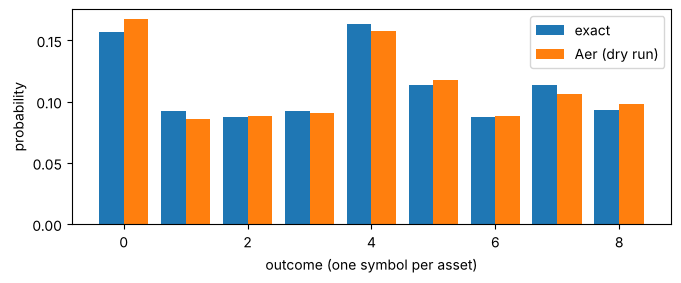

In [5]:
job = backend.run(tqc, shots=SHOTS)
if USE_AZURE:
    print("job id:", job.id())          # the job is also visible in the Azure portal under Job management
counts = job.result().get_counts()

a = qb.n_ancilla_bits(K)
freq = np.zeros(K ** N)
for key, c in counts.items():
    regs = key.split()[::-1]            # y0, y1, ... (Qiskit prints the last register first)
    j = 0
    for r in regs:
        bits = r[::-1]                  # classical bit 0 first
        y = sum(int(bits[b]) << (a - 1 - b) for b in range(a))
        j = j * K + y
    freq[j] += c
freq /= freq.sum()

tv = 0.5 * np.abs(freq - p_exact).sum()
print("total variation distance, measured vs exact:", round(float(tv), 4))
x = np.arange(K ** N)
plt.figure(figsize=(7, 3))
plt.bar(x - 0.2, p_exact, 0.4, label="exact")
plt.bar(x + 0.2, freq, 0.4, label=("Azure " + TARGET) if USE_AZURE else "Aer (dry run)")
plt.xlabel("outcome (one symbol per asset)"); plt.ylabel("probability"); plt.legend(); plt.tight_layout(); plt.show()


## Notes for the write-up

- On an ideal simulator the distance is only shot noise (about 0.03 at 1,000 shots). On a real device, noise adds to it; report both numbers and keep the device name, date and job ID.
- The `ionq.simulator`, `quantinuum` emulator and `rigetti` simulator targets run the same circuit without hardware noise or with a noise model. Use them to check the pipeline before spending hardware credits.
- Full mid-circuit-measurement runs over many days, as in notebook 1, need devices that support it and far more shots; they are future work.
- We cannot claim anything about regime detection from this run. It shows that the circuit can be sent to and read back from Azure Quantum, and how close a device gets to the exact probabilities for one step.